# Participant-level medication effects against tremor dominance

Continuous counterpart of `notebooks/2.26-participant-level-effects`. There, each participant's own
medication effect on prior use was extracted from the subtype models and the subtypes compared. Here:

1. One model **without** the score is fit to all 22 patients (the reported specification, pooled
   across the old subtypes). Each participant's effect is `col:med + u_i`.
2. Those effects are correlated with the score **draw by draw**, giving a posterior for the
   correlation that carries each participant's measurement uncertainty.
3. **How much of the heterogeneity does the score explain?** The between-participant SD of the
   medication effect, `sd_u[col:med]`, is compared between this model and the score-moderated model
   of `2.25`. If tremor dominance accounted for a real share of who responds, the SD should drop
   when the score is added.

The model in step 1 shrinks every participant toward the same mean, which pulls a correlation toward
zero. That is why the inferential test is `score:col:med` in `2.25`, which estimates the slope inside
the model. The correlation here is a descriptive, model-light view of the same question.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from config import dir_config
from src.utils.mcmc_cache import prepare_trials
from src.utils.motor_score import OUTPUT_DIR, SCORE, WITHIN, correlate, describe, fit_or_load, motor_scores

processed_dir = Path(dir_config.data.processed)
filtered_data = pd.read_csv(processed_dir / "processed_all_data_accu_60_filtered.csv", index_col=None)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
trials = prepare_trials(filtered_data, scores.index)
CATEGORY_COLOR = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B", "intermediate": "#9A9A9A"}
POSTERIOR_COLOR = "#B5541D"

## Fits

The unmoderated model on the 22 patients, and the score-moderated model from `2.25` (loaded from the
shared cache).

In [3]:
pooled = fit_or_load("pooled_22", trials)
moderated = fit_or_load("score_moderated", trials, {"score": scores["score_z"]})
diag = pooled.diagnostics()
print(f"pooled model: {pooled.divergences} divergences, max r_hat {diag['r_hat'].max():.4f}, min ESS {diag['ess_bulk'].min():.0f}")
pd.DataFrame({name: describe(pooled.term(name)) for name in pooled.names}).T.round(3)

pooled_22: loaded cached draws (seed 0, fingerprint 604eda7b7611131a)
score_moderated: loaded cached draws (seed 0, fingerprint 7d2928d58ec6fecb)
pooled model: 0 divergences, max r_hat 1.0091, min ESS 403


,mean,SD,2.5%,97.5%,P(> 0)
intercept,0.045,0.057,-0.073,0.161,0.789
coh,3.403,0.311,2.799,4.005,1.000
col,0.284,0.080,0.116,0.437,1.000
med,-0.117,0.113,-0.336,0.107,0.140
col:med,0.213,0.208,-0.191,0.646,0.848
prev_rc,0.198,0.044,0.109,0.284,1.000
prev_rc:med,-0.052,0.056,-0.163,0.060,0.168


## Participant-level effects

In [4]:
draws = pooled.term("col:med")[:, None] + pooled.deviation("col:med")  # (draw, participant)
participants = pd.Index(pooled.participants, name="participant_id")
effects = pd.DataFrame({
    "mean": draws.mean(0),
    "2.5%": np.percentile(draws, 2.5, axis=0),
    "97.5%": np.percentile(draws, 97.5, axis=0),
    "P(> 0)": (draws > 0).mean(0),
}, index=participants).join(scores[[SCORE, "category"]])
effects.sort_values(SCORE).round(3)

,mean,2.5%,97.5%,P(> 0),log2_trem_by_brady,category
participant_id,,,,,,
P22,-1.083,-1.594,-0.581,0.000,-3.366,bradykinetic
P23,-0.655,-1.169,-0.156,0.008,-2.707,bradykinetic
P1,1.205,0.658,1.778,1.000,-2.353,bradykinetic
P33,-0.260,-0.755,0.235,0.148,-2.044,bradykinetic
P20,0.209,-0.315,0.737,0.780,-1.510,bradykinetic
P28,0.759,0.229,1.293,0.998,-1.267,bradykinetic
P13,0.004,-0.496,0.515,0.511,-1.196,bradykinetic
P9,0.802,0.276,1.340,0.998,-0.781,bradykinetic
P34,0.302,-0.190,0.797,0.882,-0.459,bradykinetic


## Correlation with the score

- **Posterior of rho**: Spearman rho between the score and the 22 participant effects, computed in
  each of the 4,000 posterior draws.
- **Posterior means**: rho between the score and the participants' posterior means, with a
  permutation p-value. Treats the means as exact, so it is slightly overconfident.

In [5]:
score_vector = scores[SCORE].reindex(participants).to_numpy()
rho_draws = np.array([stats.spearmanr(score_vector, d).statistic for d in draws])
rho_summary = describe(rho_draws)
print(f"posterior of Spearman rho: mean {rho_summary['mean']:+.3f}, 95% interval [{rho_summary['2.5%']:+.3f}, {rho_summary['97.5%']:+.3f}], P(rho > 0) = {rho_summary['P(> 0)']:.3f}")
pd.Series(correlate(score_vector, effects.loc[participants, "mean"].to_numpy())).round(3)

posterior of Spearman rho: mean +0.122, 95% interval [-0.012, +0.252], P(rho > 0) = 0.962


n                22.000
spearman rho      0.159
rho 2.5%         -0.318
rho 97.5%         0.575
p (perm, rho)     0.484
pearson r         0.124
p (perm, r)       0.585
dtype: float64

## How much heterogeneity does the score explain?

Proportion of the between-participant variance in the medication effect accounted for by the score:
`1 - sd_u_moderated^2 / sd_u_pooled^2`. The two posteriors are from separate fits, so this is
computed from their posterior means (with the draw-wise ratio, pairing draws by index, as a rough
interval).

In [6]:
k = WITHIN.index("col:med")
sd_pooled, sd_moderated = pooled.sd_u[..., k].reshape(-1), moderated.sd_u[..., k].reshape(-1)
explained = 1 - sd_moderated.mean() ** 2 / sd_pooled.mean() ** 2
explained_draws = 1 - sd_moderated ** 2 / sd_pooled ** 2
heterogeneity = pd.DataFrame({"without score": describe(sd_pooled), "with score": describe(sd_moderated)}).T[["mean", "2.5%", "97.5%"]]
print(f"variance explained by the score: {explained:+.3f} (draw-wise 95% range {np.percentile(explained_draws, 2.5):+.2f} to {np.percentile(explained_draws, 97.5):+.2f})")
heterogeneity.round(3)

variance explained by the score: -0.033 (draw-wise 95% range -1.64 to +0.60)


,mean,2.5%,97.5%
without score,0.929,0.674,1.308
with score,0.944,0.671,1.314


## Figure

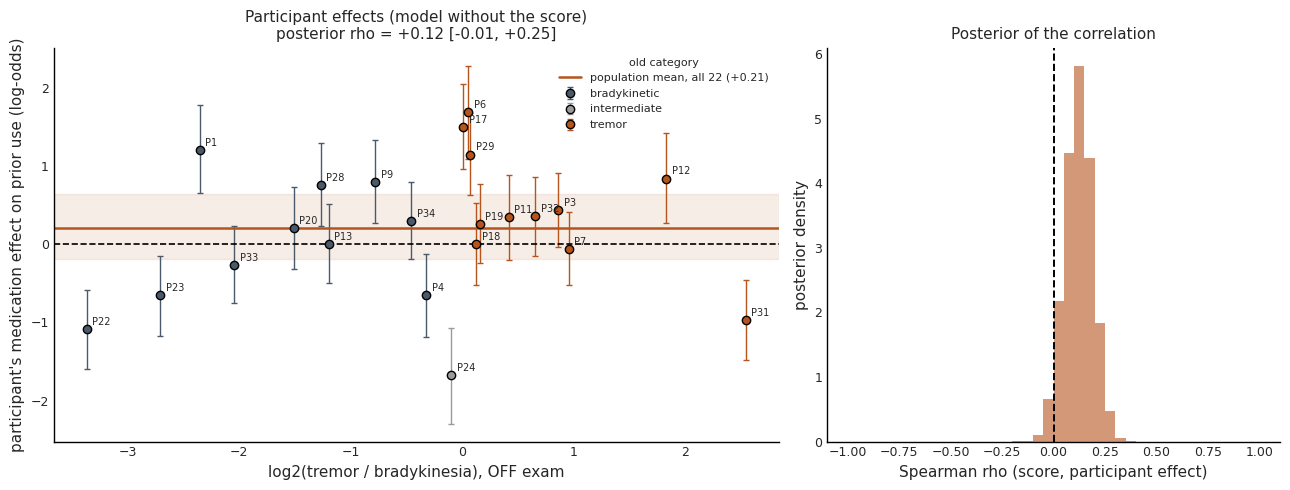

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for category, block in effects.groupby("category"):
    ax.errorbar(block[SCORE], block["mean"], yerr=[block["mean"] - block["2.5%"], block["97.5%"] - block["mean"]],
                ls="", marker="o", ms=6, mec="k", color=CATEGORY_COLOR[category], ecolor=CATEGORY_COLOR[category], capsize=2, lw=1, label=category)
for participant, row in effects.iterrows():
    ax.annotate(participant, (row[SCORE], row["mean"]), xytext=(4, 3), textcoords="offset points", fontsize=7)
pop = pooled.term("col:med")
ax.axhspan(*np.percentile(pop, [2.5, 97.5]), color=POSTERIOR_COLOR, alpha=0.1, zorder=0)
ax.axhline(pop.mean(), color=POSTERIOR_COLOR, lw=1.8, label=f"population mean, all 22 ({pop.mean():+.2f})")
ax.axhline(0, color="k", ls="--", lw=1.2)
ax.set_xlabel("log2(tremor / bradykinesia), OFF exam", fontsize=11)
ax.set_ylabel("participant's medication effect on prior use (log-odds)", fontsize=11)
ax.set_title(f"Participant effects (model without the score)\nposterior rho = {rho_summary['mean']:+.2f} [{rho_summary['2.5%']:+.2f}, {rho_summary['97.5%']:+.2f}]", fontsize=11)
ax.tick_params(labelsize=9)
ax.legend(frameon=False, fontsize=8, title="old category", title_fontsize=8)

ax = axes[1]
bins = np.linspace(-1, 1, 41)
ax.hist(rho_draws, bins=bins, color=POSTERIOR_COLOR, alpha=0.6, density=True)
ax.axvline(0, color="k", ls="--", lw=1.4)
ax.set_xlabel("Spearman rho (score, participant effect)", fontsize=11)
ax.set_ylabel("posterior density", fontsize=11)
ax.set_title("Posterior of the correlation", fontsize=11)
ax.tick_params(labelsize=9)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "participant_effects_vs_score.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "participant_effects_vs_score.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
effects.to_csv(OUTPUT_DIR / "participant_effects_vs_score.csv")
print("wrote participant_effects_vs_score.csv and figure to", OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1]))

wrote participant_effects_vs_score.csv and figure to outputs/notebooks_2


## Results

Values are from this run.

**The pooled model on all 22 patients** gives a colour x medication effect of +0.21 [-0.19, +0.65],
P(> 0) = 0.85, and a between-participant SD of 0.93 [0.67, 1.31]. Heterogeneity is about four times
the average effect.

**Participant effects barely track the score.** Spearman rho between the score and participants'
posterior means is +0.16 [-0.32, +0.58], permutation p = 0.48.

**Do not read the draw-by-draw posterior of rho as evidence.** It is +0.12 with a 95% interval of
[-0.01, +0.25] and P(rho > 0) = 0.96. That interval is narrow because it conditions on these 22
patients: it carries the uncertainty in each patient's effect but not the uncertainty from sampling
22 patients. That is the same issue as estimate 2 in `notebooks/2.27`. The permutation p-value and
the `score:col:med` slope in `2.25` answer the population question.

**The score explains no measurable share of who responds to medication.** The between-participant
SD of the medication effect is 0.93 without the score and 0.94 with it, so the proportion of variance
explained is about zero (-3%, draw-wise range -164% to +60%). Whatever makes some patients' prior
use rise with medication and others' fall, the tremor/bradykinesia balance does not account for it at
this sample size.

The caveats of `notebooks/2.26` apply unchanged. Each participant-level effect is the difference
between one OFF and one ON session, so it also contains session order, the change in
colour-orientation mapping, and day-to-day variability.